In [ ]:
!nvidia-smi

Sat Oct 24 07:03:52 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   56C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import torch
print(torch.cuda.is_available())          # True
print(torch.cuda.get_device_name(0))      # Tesla T4

True
Tesla T4


In [ ]:
!pip install ultralytics supervision

In [ ]:
from ultralytics import YOLO

model = YOLO("yolo11m.pt")
results = model.track(
    source="/content/sample_video.mp4",
    device=0,
    half=True,
    imgsz=1280,
    classes=[2, 3, 5, 7],
    conf=0.35,
    tracker="bytetrack.yaml",
    save=True,
)

In [ ]:
import glob
print(glob.glob("runs/track/*/*"))


[]


In [ ]:
import supervision as sv
from ultralytics import YOLO
import pandas as pd

model = YOLO("yolo11m.pt")
VIDEO = "/content/sample_video.mp4"
OUT = "/content/output_counted.mp4"

info = sv.VideoInfo.from_video_path(VIDEO)
W, H, FPS = info.width, info.height, info.fps

# Counting line: horizontal, 60% down the frame. Adjust to your video.
line = sv.LineZone(start=sv.Point(0, int(H * 0.6)), end=sv.Point(W, int(H * 0.6)))

box_annotator = sv.BoxAnnotator()
label_annotator = sv.LabelAnnotator()
line_annotator = sv.LineZoneAnnotator()

rows = []

def callback(frame, idx):
    r = model.track(frame, persist=True, imgsz=1280, classes=[2, 3, 5, 7],
                    conf=0.35, device=0, tracker="bytetrack.yaml",
                    verbose=False)[0]
    det = sv.Detections.from_ultralytics(r)

    # tracker_id is None on frames where nothing is tracked
    if det.tracker_id is not None and len(det) > 0:
        line.trigger(det)
        labels = [f"#{t} {model.names[c]}" for t, c in zip(det.tracker_id, det.class_id)]
        frame = box_annotator.annotate(frame, det)
        frame = label_annotator.annotate(frame, det, labels=labels)

    frame = line_annotator.annotate(frame, line)
    rows.append({"second": round(idx / FPS, 2),
                 "in": line.in_count, "out": line.out_count})
    return frame

sv.process_video(source_path=VIDEO, target_path=OUT, callback=callback)

pd.DataFrame(rows).to_csv("/content/counts.csv", index=False)
print("In:", line.in_count, "Out:", line.out_count)

In: 12 Out: 15


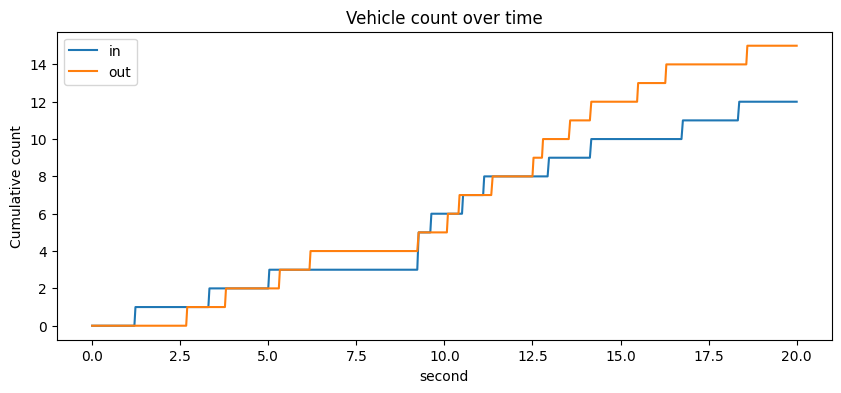

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("/content/counts.csv")
df.plot(x="second", y=["in", "out"], figsize=(10, 4))
plt.title("Vehicle count over time")
plt.ylabel("Cumulative count")
plt.savefig("/content/chart.png")
plt.show()